In [3]:
import os
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
PROJECT_ROOT = Path("..")

IMAGE_ROOT = PROJECT_ROOT / "data" / "asphalt"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"

IMAGE_OUTPUT = OUTPUT_ROOT / "images"
TABLE_OUTPUT = OUTPUT_ROOT / "tables"
RESULT_OUTPUT = OUTPUT_ROOT / "results"

IMAGE_OUTPUT.mkdir(parents=True, exist_ok=True)
TABLE_OUTPUT.mkdir(parents=True, exist_ok=True)
RESULT_OUTPUT.mkdir(parents=True, exist_ok=True)

print("Image directory:", IMAGE_ROOT)

Image directory: ../data/asphalt


In [5]:
crack_dir = IMAGE_ROOT / "crack"
non_crack_dir = IMAGE_ROOT / "non_crack"

crack_images = list(crack_dir.glob("*"))
non_crack_images = list(non_crack_dir.glob("*"))

print("Crack images:", len(crack_images))
print("Non-crack images:", len(non_crack_images))
print("Total images:", len(crack_images) + len(non_crack_images))

Crack images: 0
Non-crack images: 0
Total images: 0


In [6]:
import os
from pathlib import Path

print("Current working directory:")
print(os.getcwd())

print("\nFiles/folders here:")
for item in Path.cwd().iterdir():
    print(item)

Current working directory:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/notebooks

Files/folders here:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/notebooks/DS605_Lab6.ipynb


In [7]:
from pathlib import Path

current = Path.cwd()

print("Searching for image files...\n")

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

image_files = [
    p for p in current.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total image files found:", len(image_files))

for p in image_files[:20]:
    print(p)

Searching for image files...

Total image files found: 0


In [8]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:")
print(PROJECT_ROOT)

print("\nFolders:")
for p in PROJECT_ROOT.rglob("*"):
    if p.is_dir():
        print(p)

Project root:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction

Folders:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.vscode
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/data
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/notebooks
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/src
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/bin
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/include
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/etc
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/share
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/etc/jupyter
/Users/divyshah/

In [9]:
image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

image_files = [
    p for p in PROJECT_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_files))

for p in image_files[:20]:
    print(p)

Total images found: 435
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/ipywidgets/widgets/tests/data/jupyter-logo-transparent.png
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/IPython/core/tests/2x2.png
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/IPython/core/tests/2x2.jpg
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/datasets/images/china.jpg
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/datasets/images/flower.jpg
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/matplotlib/mpl-data/images/matplotlib_large.png
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/matplotlib/mpl-data/images/subplots_large.png
/Users/

In [10]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ASPHALT_DIR = PROJECT_ROOT / "data" / "asphalt"

print("Asphalt dataset path:")
print(ASPHALT_DIR)

print("\nContents:")
for item in ASPHALT_DIR.iterdir():
    print(item.name, "->", "Folder" if item.is_dir() else "File")

Asphalt dataset path:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/data/asphalt

Contents:
NonCracks -> Folder
.DS_Store -> File
Cracks -> Folder


In [11]:
image_extensions = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

dataset_images = [
    p for p in ASPHALT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Images inside data/asphalt only:", len(dataset_images))

for p in dataset_images[:10]:
    print(p.relative_to(PROJECT_ROOT))

Images inside data/asphalt only: 400
data/asphalt/NonCracks/IMG_8704 resized_448.jpg
data/asphalt/NonCracks/IMG_8816 resized_448.jpg
data/asphalt/NonCracks/IMG_8676 resized_448.jpg
data/asphalt/NonCracks/IMG_8697 resized_448.jpg
data/asphalt/NonCracks/IMG_8767 resized_448.jpg
data/asphalt/NonCracks/IMG_20180705_130734324 resized_448.jpg
data/asphalt/NonCracks/IMG_8786 resized_448.jpg
data/asphalt/NonCracks/IMG_8720 resized_448.jpg
data/asphalt/NonCracks/IMG_8768 resized_448.jpg
data/asphalt/NonCracks/IMG_20180705_130738321 resized_448.jpg


In [12]:
cracks_dir = ASPHALT_DIR / "Cracks"

crack_images = [
    p for p in cracks_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Images in Cracks:", len(crack_images))

for p in crack_images[:10]:
    print(p.name)

Images in Cracks: 200
IMG_8530 resized_448.jpg
IMG_8442 resized_448.jpg
IMG_20180513_165710583_HDR resized_448.jpg
IMG_20180513_170350654_HDR resized_448.jpg
IMG_8438 resized_448.jpg
IMG_8405 resized_448.jpg
IMG_20180514_170144972_HDR resized_448.jpg
IMG_20180514_170708710_HDR (1) resized_448.jpg
IMG_8487 resized_448.jpg
IMG_8529 resized_448.jpg


In [13]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ASPHALT_DIR = PROJECT_ROOT / "data" / "asphalt"

CRACK_DIR = ASPHALT_DIR / "Cracks"
NONCRACK_DIR = ASPHALT_DIR / "NonCracks"

print("Project root:", PROJECT_ROOT)
print("Cracks folder:", CRACK_DIR)
print("NonCracks folder:", NONCRACK_DIR)

print("\nCracks exists:", CRACK_DIR.exists())
print("NonCracks exists:", NONCRACK_DIR.exists())

Project root: /Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction
Cracks folder: /Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/data/asphalt/Cracks
NonCracks folder: /Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/data/asphalt/NonCracks

Cracks exists: True
NonCracks exists: True


In [14]:
image_extensions = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

crack_images = [
    p for p in CRACK_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

noncrack_images = [
    p for p in NONCRACK_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Crack images:", len(crack_images))
print("Non-crack images:", len(noncrack_images))
print("Total:", len(crack_images) + len(noncrack_images))

Crack images: 200
Non-crack images: 200
Total: 400


In [15]:
import cv2
import matplotlib.pyplot as plt

sample_path = crack_images[0]

image = cv2.imread(str(sample_path))

print("File:", sample_path.name)
print("Shape:", image.shape)
print("Height:", image.shape[0])
print("Width:", image.shape[1])
print("Channels:", image.shape[2])
print("Data type:", image.dtype)

File: IMG_8530 resized_448.jpg
Shape: (448, 448, 3)
Height: 448
Width: 448
Channels: 3
Data type: uint8


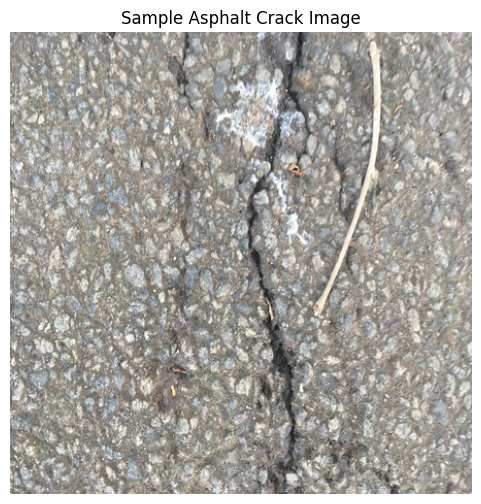

In [16]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title("Sample Asphalt Crack Image")
plt.axis("off")
plt.show()

In [17]:
IMG_SIZE = (128, 128)

In [18]:
resized = cv2.resize(image, IMG_SIZE)

gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

print("Original shape:", image.shape)
print("Resized shape:", resized.shape)
print("Grayscale shape:", gray.shape)

Original shape: (448, 448, 3)
Resized shape: (128, 128, 3)
Grayscale shape: (128, 128)


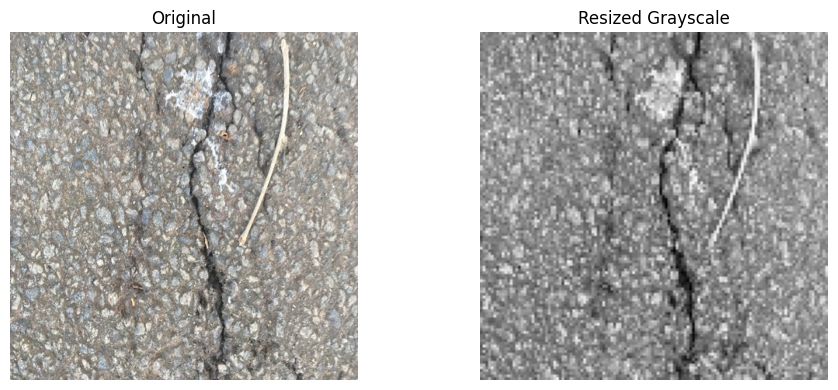

In [19]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Resized Grayscale")
plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
edges = cv2.Canny(gray, 100, 200)

edge_count = np.sum(edges > 0)
edge_density = edge_count / edges.size

print("Edge count:", edge_count)
print("Edge density:", edge_density)

Edge count: 5644
Edge density: 0.344482421875


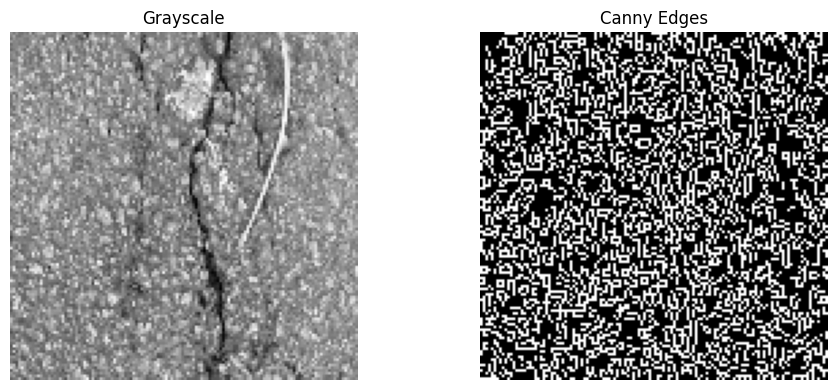

In [21]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
def extract_image_features(
    image_path,
    image_size=(128, 128),
    canny_low=100,
    canny_high=200
):
    
    # Read image
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    # Resize
    resized = cv2.resize(image, image_size)

    # Convert to grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # -----------------------------
    # Intensity features
    # -----------------------------
    mean_brightness = np.mean(gray)
    std_brightness = np.std(gray)
    median_brightness = np.median(gray)

    min_intensity = np.min(gray)
    max_intensity = np.max(gray)

    # Contrast
    contrast = np.std(gray)

    # -----------------------------
    # Pixel ratios
    # -----------------------------
    dark_pixel_ratio = np.mean(gray < 50)
    bright_pixel_ratio = np.mean(gray > 200)

    # -----------------------------
    # Intensity percentiles
    # -----------------------------
    p10 = np.percentile(gray, 10)
    p25 = np.percentile(gray, 25)
    p50 = np.percentile(gray, 50)
    p75 = np.percentile(gray, 75)
    p90 = np.percentile(gray, 90)

    # -----------------------------
    # Canny edge features
    # -----------------------------
    edges = cv2.Canny(
        gray,
        canny_low,
        canny_high
    )

    edge_count = np.sum(edges > 0)

    edge_density = edge_count / edges.size

    return {
        "mean_brightness": mean_brightness,
        "std_brightness": std_brightness,
        "median_brightness": median_brightness,
        "contrast": contrast,
        "min_intensity": min_intensity,
        "max_intensity": max_intensity,
        "dark_pixel_ratio": dark_pixel_ratio,
        "bright_pixel_ratio": bright_pixel_ratio,
        "p10": p10,
        "p25": p25,
        "p50": p50,
        "p75": p75,
        "p90": p90,
        "edge_count": edge_count,
        "edge_density": edge_density
    }

In [23]:
test_features = extract_image_features(crack_images[0])

test_features

{'mean_brightness': np.float64(154.88238525390625),
 'std_brightness': np.float64(31.640280048644602),
 'median_brightness': np.float64(152.0),
 'contrast': np.float64(31.640280048644602),
 'min_intensity': np.uint8(32),
 'max_intensity': np.uint8(254),
 'dark_pixel_ratio': np.float64(0.00299072265625),
 'bright_pixel_ratio': np.float64(0.0897216796875),
 'p10': np.float64(120.0),
 'p25': np.float64(135.0),
 'p50': np.float64(152.0),
 'p75': np.float64(173.0),
 'p90': np.float64(198.0),
 'edge_count': np.int64(5644),
 'edge_density': np.float64(0.344482421875)}

In [24]:
records = []

# -----------------------------
# Crack images
# -----------------------------
for image_path in crack_images:

    features = extract_image_features(image_path)

    if features is not None:
        features["filename"] = image_path.name
        features["label"] = "crack"

        records.append(features)


# -----------------------------
# Non-crack images
# -----------------------------
for image_path in noncrack_images:

    features = extract_image_features(image_path)

    if features is not None:
        features["filename"] = image_path.name
        features["label"] = "non_crack"

        records.append(features)


image_features_df = pd.DataFrame(records)

print("Feature table shape:", image_features_df.shape)

image_features_df.head()

Feature table shape: (400, 17)


,mean_brightness,std_brightness,median_brightness,contrast,min_intensity,max_intensity,dark_pixel_ratio,bright_pixel_ratio,p10,p25,p50,p75,p90,edge_count,edge_density,filename,label
0,154.882385,31.640280,152.0,31.640280,32,254,0.002991,0.089722,120.0,135.0,152.0,173.0,198.0,5644,0.344482,IMG_8530 resized_448.jpg,crack
1,143.220459,47.688031,146.0,47.688031,23,253,0.024902,0.122131,75.0,109.0,146.0,180.0,205.0,6207,0.378845,IMG_8442 resized_448.jpg,crack
2,130.121765,29.300121,132.0,29.300121,7,252,0.008606,0.006042,92.0,113.0,132.0,150.0,164.0,5296,0.323242,IMG_20180513_165710583_HDR resized_448.jpg,crack
3,129.480957,21.111379,132.0,21.111379,8,233,0.001892,0.001953,102.0,118.0,132.0,143.0,153.0,3348,0.204346,IMG_20180513_170350654_HDR resized_448.jpg,crack
4,139.634155,47.783950,142.0,47.783950,19,252,0.029907,0.105591,72.0,105.0,142.0,176.0,202.0,6010,0.366821,IMG_8438 resized_448.jpg,crack


In [25]:
print("Total rows:", len(image_features_df))

print("\nClass distribution:")
print(image_features_df["label"].value_counts())

print("\nMissing values:")
print(image_features_df.isnull().sum())

print("\nFeature columns:")
print(image_features_df.columns.tolist())

Total rows: 400

Class distribution:
label
crack        200
non_crack    200
Name: count, dtype: int64

Missing values:
mean_brightness       0
std_brightness        0
median_brightness     0
contrast              0
min_intensity         0
max_intensity         0
dark_pixel_ratio      0
bright_pixel_ratio    0
p10                   0
p25                   0
p50                   0
p75                   0
p90                   0
edge_count            0
edge_density          0
filename              0
label                 0
dtype: int64

Feature columns:
['mean_brightness', 'std_brightness', 'median_brightness', 'contrast', 'min_intensity', 'max_intensity', 'dark_pixel_ratio', 'bright_pixel_ratio', 'p10', 'p25', 'p50', 'p75', 'p90', 'edge_count', 'edge_density', 'filename', 'label']


In [26]:
TABLE_OUTPUT = PROJECT_ROOT / "outputs" / "tables"

TABLE_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

feature_file = TABLE_OUTPUT / "image_features.csv"

image_features_df.to_csv(
    feature_file,
    index=False
)

print("Saved to:")
print(feature_file)

Saved to:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs/tables/image_features.csv


In [27]:
print(image_features_df.shape)
print(image_features_df["label"].value_counts())
image_features_df.head()

(400, 17)
label
crack        200
non_crack    200
Name: count, dtype: int64


,mean_brightness,std_brightness,median_brightness,contrast,min_intensity,max_intensity,dark_pixel_ratio,bright_pixel_ratio,p10,p25,p50,p75,p90,edge_count,edge_density,filename,label
0,154.882385,31.640280,152.0,31.640280,32,254,0.002991,0.089722,120.0,135.0,152.0,173.0,198.0,5644,0.344482,IMG_8530 resized_448.jpg,crack
1,143.220459,47.688031,146.0,47.688031,23,253,0.024902,0.122131,75.0,109.0,146.0,180.0,205.0,6207,0.378845,IMG_8442 resized_448.jpg,crack
2,130.121765,29.300121,132.0,29.300121,7,252,0.008606,0.006042,92.0,113.0,132.0,150.0,164.0,5296,0.323242,IMG_20180513_165710583_HDR resized_448.jpg,crack
3,129.480957,21.111379,132.0,21.111379,8,233,0.001892,0.001953,102.0,118.0,132.0,143.0,153.0,3348,0.204346,IMG_20180513_170350654_HDR resized_448.jpg,crack
4,139.634155,47.783950,142.0,47.783950,19,252,0.029907,0.105591,72.0,105.0,142.0,176.0,202.0,6010,0.366821,IMG_8438 resized_448.jpg,crack


In [28]:
# Separate features and labels

X = image_features_df.drop(
    columns=["filename", "label"]
)

y = image_features_df["label"].map({
    "non_crack": 0,
    "crack": 1
})

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nLabels:")
print(y.value_counts())

X shape: (400, 15)
y shape: (400,)

Feature columns:
['mean_brightness', 'std_brightness', 'median_brightness', 'contrast', 'min_intensity', 'max_intensity', 'dark_pixel_ratio', 'bright_pixel_ratio', 'p10', 'p25', 'p50', 'p75', 'p90', 'edge_count', 'edge_density']

Labels:
label
1    200
0    200
Name: count, dtype: int64


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 320
Testing samples: 80

Training class distribution:
label
1    160
0    160
Name: count, dtype: int64

Testing class distribution:
label
0    40
1    40
Name: count, dtype: int64


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [31]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf"
        ))
    ])
}

print("Models prepared:")
for name in models:
    print("-", name)

Models prepared:
- Logistic Regression
- Random Forest
- SVM


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [33]:
import time

In [34]:
results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Training time
    start_train = time.perf_counter()

    model.fit(X_train, y_train)

    end_train = time.perf_counter()

    train_time = end_train - start_train

    # Prediction time
    start_pred = time.perf_counter()

    y_pred = model.predict(X_test)

    end_pred = time.perf_counter()

    prediction_time = end_pred - start_pred

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # Store
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (s)": train_time,
        "Prediction Time (s)": prediction_time
    })

    trained_models[name] = model
    predictions[name] = y_pred

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Training Time: {train_time:.6f} sec")
    print(f"Prediction Time: {prediction_time:.6f} sec")


Training Logistic Regression...
Accuracy: 0.9375
Precision: 0.9487
Recall: 0.9250
F1 Score: 0.9367
Training Time: 0.013327 sec
Prediction Time: 0.004093 sec

Training Random Forest...
Accuracy: 0.9625
Precision: 0.9512
Recall: 0.9750
F1 Score: 0.9630
Training Time: 0.109012 sec
Prediction Time: 0.015319 sec

Training SVM...
Accuracy: 0.9625
Precision: 0.9512
Recall: 0.9750
F1 Score: 0.9630
Training Time: 0.001821 sec
Prediction Time: 0.000635 sec


/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/divyshah/Desktop/DS605_L

In [35]:
image_results_df = pd.DataFrame(results)

image_results_df

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.9375,0.948718,0.925,0.936709,0.013327,0.004093
1,Random Forest,0.9625,0.951220,0.975,0.962963,0.109012,0.015319
2,SVM,0.9625,0.951220,0.975,0.962963,0.001821,0.000635


In [36]:
display(
    image_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Training Time (s)": "{:.6f}",
        "Prediction Time (s)": "{:.6f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.9375,0.9487,0.9250,0.9367,0.013327,0.004093
1,Random Forest,0.9625,0.9512,0.9750,0.9630,0.109012,0.015319
2,SVM,0.9625,0.9512,0.9750,0.9630,0.001821,0.000635


In [37]:
RESULT_OUTPUT = PROJECT_ROOT / "outputs" / "results"

RESULT_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

image_results_df.to_csv(
    RESULT_OUTPUT / "image_model_results.csv",
    index=False
)

print("Saved:")
print(RESULT_OUTPUT / "image_model_results.csv")

Saved:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs/results/image_model_results.csv


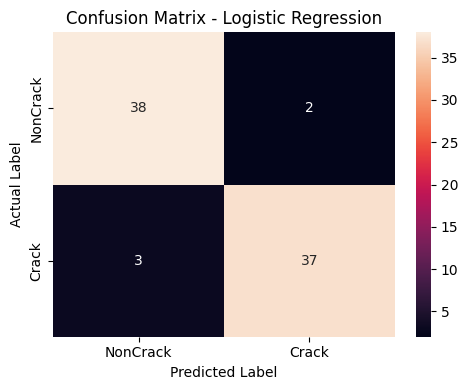

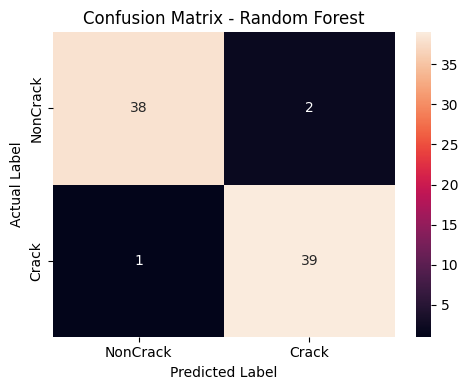

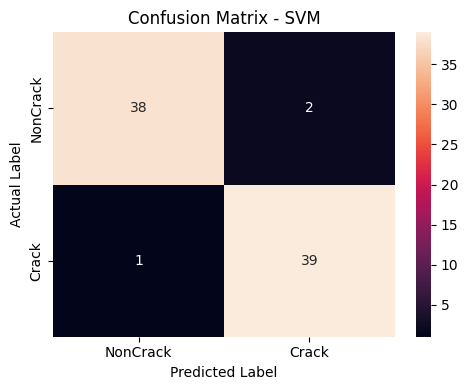

In [38]:
for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["NonCrack", "Crack"],
        yticklabels=["NonCrack", "Crack"]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"Confusion Matrix - {name}")

    plt.tight_layout()

    filename = (
        name.lower()
        .replace(" ", "_")
    )

    plt.savefig(
        RESULT_OUTPUT / f"{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [39]:
for name, y_pred in predictions.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["NonCrack", "Crack"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    NonCrack       0.93      0.95      0.94        40
       Crack       0.95      0.93      0.94        40

    accuracy                           0.94        80
   macro avg       0.94      0.94      0.94        80
weighted avg       0.94      0.94      0.94        80

Random Forest
              precision    recall  f1-score   support

    NonCrack       0.97      0.95      0.96        40
       Crack       0.95      0.97      0.96        40

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80

SVM
              precision    recall  f1-score   support

    NonCrack       0.97      0.95      0.96        40
       Crack       0.95      0.97      0.96        40

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96   

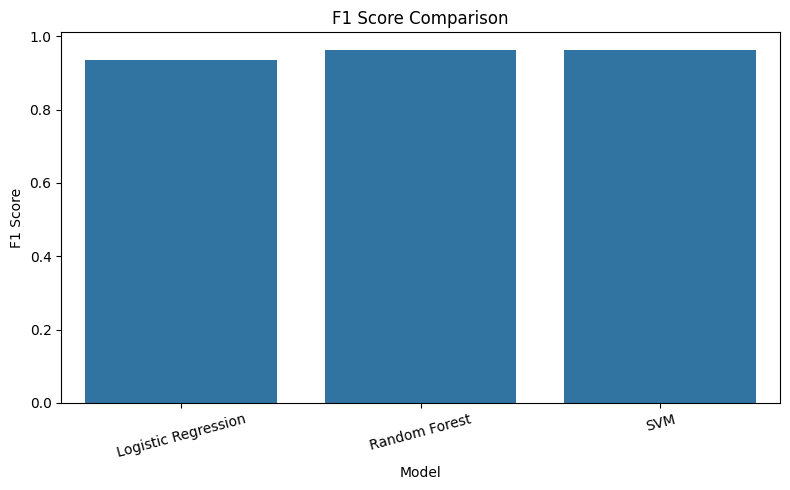

In [40]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=image_results_df,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison")
plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

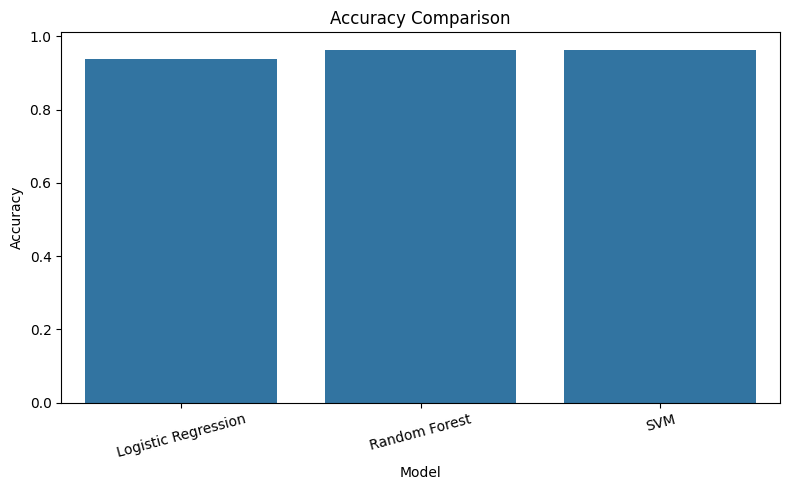

In [41]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=image_results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

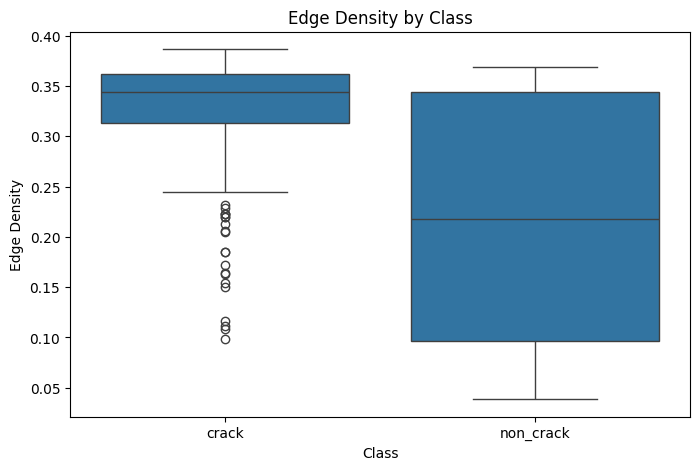

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=image_features_df,
    x="label",
    y="edge_density"
)

plt.title("Edge Density by Class")
plt.xlabel("Class")
plt.ylabel("Edge Density")

plt.show()

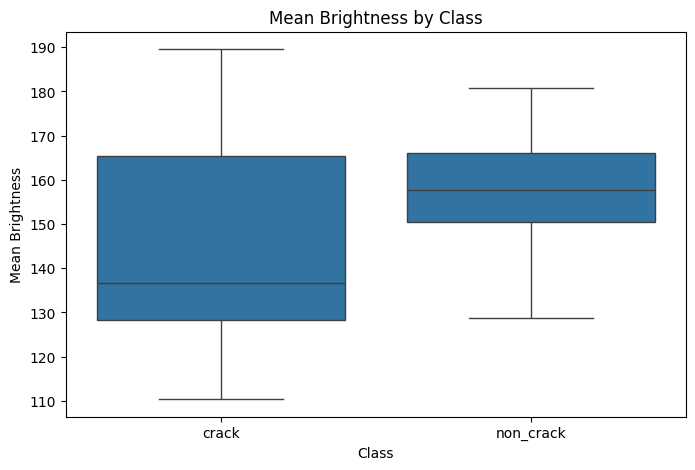

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=image_features_df,
    x="label",
    y="mean_brightness"
)

plt.title("Mean Brightness by Class")
plt.xlabel("Class")
plt.ylabel("Mean Brightness")

plt.show()

In [44]:
IMPROVED_CANNY_LOW = 50
IMPROVED_CANNY_HIGH = 150

print("Original Canny thresholds: 100, 200")
print("Improved Canny thresholds:", IMPROVED_CANNY_LOW, IMPROVED_CANNY_HIGH)

Original Canny thresholds: 100, 200
Improved Canny thresholds: 50 150


In [45]:
def extract_improved_image_features(
    image_path,
    image_size=(128, 128),
    canny_low=50,
    canny_high=150
):
    
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    resized = cv2.resize(image, image_size)

    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # Intensity features
    mean_brightness = np.mean(gray)
    std_brightness = np.std(gray)
    median_brightness = np.median(gray)

    min_intensity = np.min(gray)
    max_intensity = np.max(gray)

    contrast = np.std(gray)

    # Pixel ratios
    dark_pixel_ratio = np.mean(gray < 50)
    bright_pixel_ratio = np.mean(gray > 200)

    # Percentiles
    p10 = np.percentile(gray, 10)
    p25 = np.percentile(gray, 25)
    p50 = np.percentile(gray, 50)
    p75 = np.percentile(gray, 75)
    p90 = np.percentile(gray, 90)

    # Improved Canny
    edges = cv2.Canny(
        gray,
        canny_low,
        canny_high
    )

    edge_count = np.sum(edges > 0)
    edge_density = edge_count / edges.size

    return {
        "mean_brightness": mean_brightness,
        "std_brightness": std_brightness,
        "median_brightness": median_brightness,
        "contrast": contrast,
        "min_intensity": min_intensity,
        "max_intensity": max_intensity,
        "dark_pixel_ratio": dark_pixel_ratio,
        "bright_pixel_ratio": bright_pixel_ratio,
        "p10": p10,
        "p25": p25,
        "p50": p50,
        "p75": p75,
        "p90": p90,
        "edge_count": edge_count,
        "edge_density": edge_density
    }

In [46]:
improved_records = []

# Crack images
for image_path in crack_images:

    features = extract_improved_image_features(image_path)

    if features is not None:
        features["filename"] = image_path.name
        features["label"] = "crack"
        improved_records.append(features)


# Non-crack images
for image_path in noncrack_images:

    features = extract_improved_image_features(image_path)

    if features is not None:
        features["filename"] = image_path.name
        features["label"] = "non_crack"
        improved_records.append(features)


improved_image_features_df = pd.DataFrame(improved_records)

print("Improved dataset shape:", improved_image_features_df.shape)
print("\nClass distribution:")
print(improved_image_features_df["label"].value_counts())

Improved dataset shape: (400, 17)

Class distribution:
label
crack        200
non_crack    200
Name: count, dtype: int64


In [47]:
print("Original edge density:")
print(image_features_df["edge_density"].describe())

print("\nImproved edge density:")
print(improved_image_features_df["edge_density"].describe())

Original edge density:
count    400.000000
mean       0.271553
std        0.104787
min        0.038757
25%        0.186478
50%        0.324188
75%        0.353622
max        0.386597
Name: edge_density, dtype: float64

Improved edge density:
count    400.000000
mean       0.353003
std        0.028847
min        0.243530
25%        0.342834
50%        0.363983
75%        0.372452
max        0.391968
Name: edge_density, dtype: float64


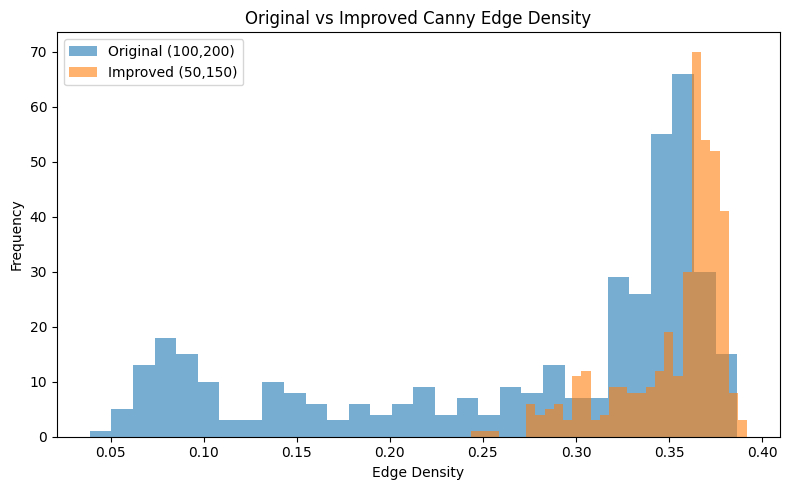

In [48]:
plt.figure(figsize=(8, 5))

plt.hist(
    image_features_df["edge_density"],
    bins=30,
    alpha=0.6,
    label="Original (100,200)"
)

plt.hist(
    improved_image_features_df["edge_density"],
    bins=30,
    alpha=0.6,
    label="Improved (50,150)"
)

plt.xlabel("Edge Density")
plt.ylabel("Frequency")
plt.title("Original vs Improved Canny Edge Density")
plt.legend()

plt.tight_layout()
plt.show()

In [49]:
X_improved = improved_image_features_df.drop(
    columns=["filename", "label"]
)

y_improved = improved_image_features_df["label"].map({
    "non_crack": 0,
    "crack": 1
})

In [50]:
X_train_imp, X_test_imp, y_train_imp, y_test_imp = train_test_split(
    X_improved,
    y_improved,
    test_size=0.20,
    random_state=42,
    stratify=y_improved
)

print("Improved training samples:", len(X_train_imp))
print("Improved testing samples:", len(X_test_imp))

Improved training samples: 320
Improved testing samples: 80


In [51]:
improved_results = []

improved_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf"))
    ])
}

In [52]:
improved_trained_models = {}
improved_predictions = {}

for name, model in improved_models.items():

    print(f"\nTraining improved {name}...")

    start_train = time.perf_counter()

    model.fit(X_train_imp, y_train_imp)

    train_time = time.perf_counter() - start_train

    start_pred = time.perf_counter()

    y_pred = model.predict(X_test_imp)

    prediction_time = time.perf_counter() - start_pred

    accuracy = accuracy_score(y_test_imp, y_pred)
    precision = precision_score(
        y_test_imp,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test_imp,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test_imp,
        y_pred,
        zero_division=0
    )

    improved_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (s)": train_time,
        "Prediction Time (s)": prediction_time
    })

    improved_trained_models[name] = model
    improved_predictions[name] = y_pred


Training improved Logistic Regression...

Training improved Random Forest...

Training improved SVM...


/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/divyshah/Desktop/DS605_L

In [53]:
improved_image_results_df = pd.DataFrame(improved_results)

display(
    improved_image_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Training Time (s)": "{:.6f}",
        "Prediction Time (s)": "{:.6f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.9375,0.9487,0.9250,0.9367,0.005003,0.000836
1,Random Forest,0.9375,0.9268,0.9500,0.9383,0.103912,0.013227
2,SVM,0.9625,0.9512,0.9750,0.9630,0.001573,0.000617


In [54]:
original_compare = image_results_df.copy()
original_compare["Representation"] = "Original Canny (100,200)"

improved_compare = improved_image_results_df.copy()
improved_compare["Representation"] = "Improved Canny (50,150)"

comparison_df = pd.concat(
    [original_compare, improved_compare],
    ignore_index=True
)

comparison_df = comparison_df[
    [
        "Representation",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Training Time (s)",
        "Prediction Time (s)"
    ]
]

comparison_df

,Representation,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,"Original Canny (100,200)",Logistic Regression,0.9375,0.948718,0.925,0.936709,0.013327,0.004093
1,"Original Canny (100,200)",Random Forest,0.9625,0.951220,0.975,0.962963,0.109012,0.015319
2,"Original Canny (100,200)",SVM,0.9625,0.951220,0.975,0.962963,0.001821,0.000635
3,"Improved Canny (50,150)",Logistic Regression,0.9375,0.948718,0.925,0.936709,0.005003,0.000836
4,"Improved Canny (50,150)",Random Forest,0.9375,0.926829,0.950,0.938272,0.103912,0.013227
5,"Improved Canny (50,150)",SVM,0.9625,0.951220,0.975,0.962963,0.001573,0.000617


In [55]:
comparison_df.to_csv(
    RESULT_OUTPUT / "image_original_vs_improved.csv",
    index=False
)

print("Saved:")
print(RESULT_OUTPUT / "image_original_vs_improved.csv")

Saved:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs/results/image_original_vs_improved.csv


In [56]:
f1_comparison = comparison_df.pivot(
    index="Model",
    columns="Representation",
    values="F1 Score"
)

f1_comparison["F1 Change"] = (
    f1_comparison["Improved Canny (50,150)"]
    - f1_comparison["Original Canny (100,200)"]
)

f1_comparison

Representation,"Improved Canny (50,150)","Original Canny (100,200)",F1 Change
Model,,,
Logistic Regression,0.936709,0.936709,0.000000
Random Forest,0.938272,0.962963,-0.024691
SVM,0.962963,0.962963,0.000000


In [57]:
accuracy_comparison = comparison_df.pivot(
    index="Model",
    columns="Representation",
    values="Accuracy"
)

accuracy_comparison["Accuracy Change"] = (
    accuracy_comparison["Improved Canny (50,150)"]
    - accuracy_comparison["Original Canny (100,200)"]
)

accuracy_comparison

Representation,"Improved Canny (50,150)","Original Canny (100,200)",Accuracy Change
Model,,,
Logistic Regression,0.9375,0.9375,0.000
Random Forest,0.9375,0.9625,-0.025
SVM,0.9625,0.9625,0.000


In [58]:
improved_image_features_df.to_csv(
    TABLE_OUTPUT / "improved_image_features.csv",
    index=False
)

In [59]:
# ==============================
# PART B - EMAIL SPAM CLASSIFICATION
# ==============================

EMAIL_FILE = PROJECT_ROOT / "data" / "email" / "emails.csv"

email_df = pd.read_csv(
    EMAIL_FILE,
    encoding="latin-1"
)

print("Dataset shape:", email_df.shape)

print("\nColumns:")
print(email_df.columns.tolist())

print("\nFirst 5 rows:")
display(email_df.head())

Dataset shape: (5172, 3002)

Columns:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', 'here',

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [60]:
print(email_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB
None


In [61]:
print("\nMissing values:")
print(email_df.isnull().sum())

print("\nDuplicate rows:")
print(email_df.duplicated().sum())


Missing values:
Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

Duplicate rows:
0


In [62]:
print("\nDuplicate rows:", email_df.duplicated().sum())


Duplicate rows: 0


In [64]:
print("Columns in emails.csv:")
print(email_df.columns.tolist())

print("\nFirst 5 rows:")
display(email_df.head())

Columns in emails.csv:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', 'here', 'like', 'b', '

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [65]:
print(email_df.shape)
print(email_df.dtypes)

(5172, 3002)
Email No.     object
the            int64
to             int64
ect            int64
and            int64
               ...  
military       int64
allowing       int64
ff             int64
dry            int64
Prediction     int64
Length: 3002, dtype: object


In [67]:
# Inspect the actual email dataset structure

print("Dataset shape:")
print(email_df.shape)

print("\nExact column names:")
for i, col in enumerate(email_df.columns):
    print(i, repr(col))

print("\nFirst 5 rows:")
display(email_df.head())

Dataset shape:
(5172, 3002)

Exact column names:
0 'Email No.'
1 'the'
2 'to'
3 'ect'
4 'and'
5 'for'
6 'of'
7 'a'
8 'you'
9 'hou'
10 'in'
11 'on'
12 'is'
13 'this'
14 'enron'
15 'i'
16 'be'
17 'that'
18 'will'
19 'have'
20 'with'
21 'your'
22 'at'
23 'we'
24 's'
25 'are'
26 'it'
27 'by'
28 'com'
29 'as'
30 'from'
31 'gas'
32 'or'
33 'not'
34 'me'
35 'deal'
36 'if'
37 'meter'
38 'hpl'
39 'please'
40 're'
41 'e'
42 'any'
43 'our'
44 'corp'
45 'can'
46 'd'
47 'all'
48 'has'
49 'was'
50 'know'
51 'need'
52 'an'
53 'forwarded'
54 'new'
55 't'
56 'may'
57 'up'
58 'j'
59 'mmbtu'
60 'should'
61 'do'
62 'am'
63 'get'
64 'out'
65 'see'
66 'no'
67 'there'
68 'price'
69 'daren'
70 'but'
71 'been'
72 'company'
73 'l'
74 'these'
75 'let'
76 'so'
77 'would'
78 'm'
79 'into'
80 'xls'
81 'farmer'
82 'attached'
83 'us'
84 'information'
85 'they'
86 'message'
87 'day'
88 'time'
89 'my'
90 'one'
91 'what'
92 'only'
93 'http'
94 'th'
95 'volume'
96 'mail'
97 'contract'
98 'which'
99 'month'
100 'more'
101

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [68]:
print("\nData types:")
print(email_df.dtypes)


Data types:
Email No.     object
the            int64
to             int64
ect            int64
and            int64
               ...  
military       int64
allowing       int64
ff             int64
dry            int64
Prediction     int64
Length: 3002, dtype: object


In [70]:
print("Shape:", email_df.shape)

print("\nFirst 5 columns:")
print(email_df.columns[:5].tolist())

print("\nLast 5 columns:")
print(email_df.columns[-5:].tolist())

display(email_df.head())

Shape: (5172, 3002)

First 5 columns:
['Email No.', 'the', 'to', 'ect', 'and']

Last 5 columns:
['military', 'allowing', 'ff', 'dry', 'Prediction']


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [72]:
LABEL_COLUMN = "Prediction"
ID_COLUMN = "Email No."

WORD_COLUMNS = [
    col for col in email_df.columns
    if col not in [ID_COLUMN, LABEL_COLUMN]
]

print("Number of word columns:", len(WORD_COLUMNS))

Number of word columns: 3000


In [73]:
print(
    email_df[LABEL_COLUMN].value_counts()
)

Prediction
0    3672
1    1500
Name: count, dtype: int64


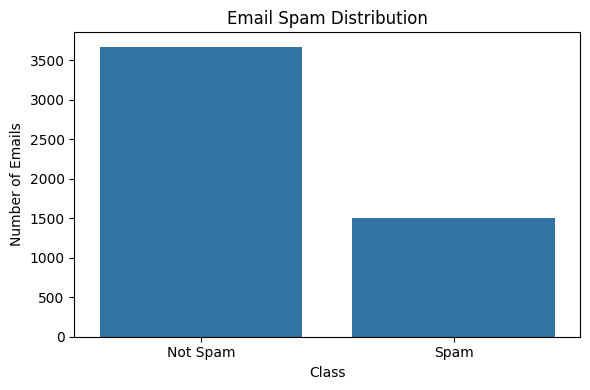

In [74]:
plt.figure(figsize=(6, 4))

sns.countplot(
    x=email_df[LABEL_COLUMN].map({
        0: "Not Spam",
        1: "Spam"
    })
)

plt.title("Email Spam Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Emails")

plt.tight_layout()
plt.show()

In [75]:
def reconstruct_text(row):
    words = []

    for word in WORD_COLUMNS:
        count = int(row[word])

        if count > 0:
            words.extend([word] * count)

    return " ".join(words)

In [76]:
sample_text = reconstruct_text(email_df.iloc[0])

print(sample_text[:1000])

ect a a is i i s s s as re re e e e e t t t t j m m b p c c c r r r r f h u u tu st ic far chris hr rm tr pictures pi ma picture ct ct christmas ur tm


In [77]:
print("Reconstructing email text...")

email_df["text"] = email_df.apply(
    reconstruct_text,
    axis=1
)

print("Done!")

display(
    email_df[["Email No.", "text", "Prediction"]].head()
)

Reconstructing email text...
Done!


,Email No.,text,Prediction
0,Email 1,ect a a is i i s s s as re re e e e e t t t t ...,0
1,Email 2,the the the the the the the the to to to to to...,0
2,Email 3,ect a a a a a a a a in in in in on on i i i i ...,0
3,Email 4,to to to to to ect ect ect ect ect ect ect ect...,0
4,Email 5,the the the the the the the to to to to to to ...,0


In [78]:
import re

def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Keep alphabetic characters and spaces
    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

In [79]:
email_df["clean_text"] = email_df["text"].apply(
    clean_text
)

In [80]:
display(
    email_df[
        ["text", "clean_text", "Prediction"]
    ].head()
)

,text,clean_text,Prediction
0,ect a a is i i s s s as re re e e e e t t t t ...,ect a a is i i s s s as re re e e e e t t t t ...,0
1,the the the the the the the the to to to to to...,the the the the the the the the to to to to to...,0
2,ect a a a a a a a a in in in in on on i i i i ...,ect a a a a a a a a in in in in on on i i i i ...,0
3,to to to to to ect ect ect ect ect ect ect ect...,to to to to to ect ect ect ect ect ect ect ect...,0
4,the the the the the the the to to to to to to ...,the the the the the the the to to to to to to ...,0


In [81]:
X_text = email_df["clean_text"]

y_text = email_df["Prediction"]

print("X:", X_text.shape)
print("y:", y_text.shape)

print("\nLabel distribution:")
print(y_text.value_counts())

X: (5172,)
y: (5172,)

Label distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [82]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    X_text,
    y_text,
    test_size=0.20,
    random_state=42,
    stratify=y_text
)

print("Training emails:", len(X_train_text))
print("Testing emails:", len(X_test_text))

Training emails: 4137
Testing emails: 1035


In [83]:
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer()

X_train_count = count_vectorizer.fit_transform(
    X_train_text
)

X_test_count = count_vectorizer.transform(
    X_test_text
)

print("CountVectorizer training shape:",
      X_train_count.shape)

print("CountVectorizer testing shape:",
      X_test_count.shape)

CountVectorizer training shape: (4137, 2974)
CountVectorizer testing shape: (1035, 2974)


In [84]:
count_feature_count = X_train_count.shape[1]

print(
    "CountVectorizer features:",
    count_feature_count
)

CountVectorizer features: 2974


In [85]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train_text
)

X_test_tfidf = tfidf_vectorizer.transform(
    X_test_text
)

print("TF-IDF training shape:",
      X_train_tfidf.shape)

print("TF-IDF testing shape:",
      X_test_tfidf.shape)

TF-IDF training shape: (4137, 2974)
TF-IDF testing shape: (1035, 2974)


In [86]:
tfidf_feature_count = X_train_tfidf.shape[1]

print(
    "TF-IDF features:",
    tfidf_feature_count
)

TF-IDF features: 2974


In [87]:
from sklearn.linear_model import LogisticRegression

count_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

tfidf_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

In [88]:
start_train = time.perf_counter()

count_model.fit(
    X_train_count,
    y_train_text
)

count_train_time = time.perf_counter() - start_train

start_pred = time.perf_counter()

count_pred = count_model.predict(
    X_test_count
)

count_prediction_time = time.perf_counter() - start_pred

/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: invalid value encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)


In [89]:
start_train = time.perf_counter()

tfidf_model.fit(
    X_train_tfidf,
    y_train_text
)

tfidf_train_time = time.perf_counter() - start_train

start_pred = time.perf_counter()

tfidf_pred = tfidf_model.predict(
    X_test_tfidf
)

tfidf_prediction_time = time.perf_counter() - start_pred

/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: invalid value encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)


In [90]:
count_accuracy = accuracy_score(
    y_test_text,
    count_pred
)

count_precision = precision_score(
    y_test_text,
    count_pred,
    zero_division=0
)

count_recall = recall_score(
    y_test_text,
    count_pred,
    zero_division=0
)

count_f1 = f1_score(
    y_test_text,
    count_pred,
    zero_division=0
)


tfidf_accuracy = accuracy_score(
    y_test_text,
    tfidf_pred
)

tfidf_precision = precision_score(
    y_test_text,
    tfidf_pred,
    zero_division=0
)

tfidf_recall = recall_score(
    y_test_text,
    tfidf_pred,
    zero_division=0
)

tfidf_f1 = f1_score(
    y_test_text,
    tfidf_pred,
    zero_division=0
)

In [91]:
text_results_df = pd.DataFrame([
    {
        "Representation": "CountVectorizer",
        "Features": count_feature_count,
        "Accuracy": count_accuracy,
        "Precision": count_precision,
        "Recall": count_recall,
        "F1 Score": count_f1,
        "Training Time (s)": count_train_time,
        "Prediction Time (s)": count_prediction_time
    },
    {
        "Representation": "TF-IDF",
        "Features": tfidf_feature_count,
        "Accuracy": tfidf_accuracy,
        "Precision": tfidf_precision,
        "Recall": tfidf_recall,
        "F1 Score": tfidf_f1,
        "Training Time (s)": tfidf_train_time,
        "Prediction Time (s)": tfidf_prediction_time
    }
])

display(
    text_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Training Time (s)": "{:.6f}",
        "Prediction Time (s)": "{:.6f}"
    })
)

,Representation,Features,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,CountVectorizer,2974,0.9807,0.9545,0.9800,0.9671,0.146906,0.000259
1,TF-IDF,2974,0.9768,0.9510,0.9700,0.9604,0.022609,0.000408


In [92]:
text_results_df.to_csv(
    RESULT_OUTPUT / "text_vectorization_comparison.csv",
    index=False
)

In [93]:
text_results_df = pd.DataFrame([
    {
        "Representation": "CountVectorizer",
        "Features": count_feature_count,
        "Accuracy": count_accuracy,
        "Precision": count_precision,
        "Recall": count_recall,
        "F1 Score": count_f1,
        "Training Time (s)": count_train_time,
        "Prediction Time (s)": count_prediction_time
    },
    {
        "Representation": "TF-IDF",
        "Features": tfidf_feature_count,
        "Accuracy": tfidf_accuracy,
        "Precision": tfidf_precision,
        "Recall": tfidf_recall,
        "F1 Score": tfidf_f1,
        "Training Time (s)": tfidf_train_time,
        "Prediction Time (s)": tfidf_prediction_time
    }
])

display(
    text_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Training Time (s)": "{:.6f}",
        "Prediction Time (s)": "{:.6f}"
    })
)

,Representation,Features,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,CountVectorizer,2974,0.9807,0.9545,0.9800,0.9671,0.146906,0.000259
1,TF-IDF,2974,0.9768,0.9510,0.9700,0.9604,0.022609,0.000408


In [94]:
text_results_df.to_csv(
    RESULT_OUTPUT / "text_vectorization_comparison.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


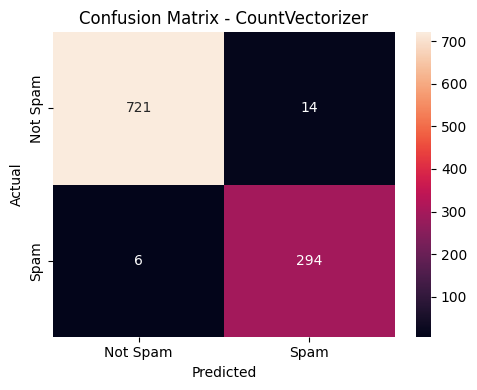

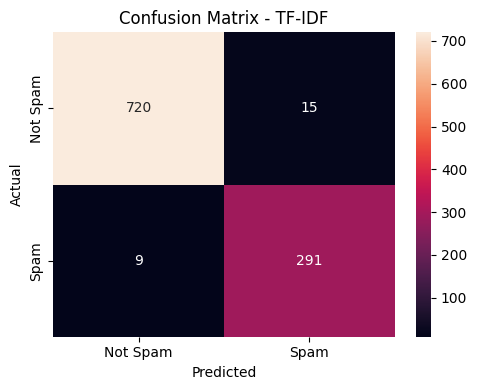

In [95]:
text_predictions = {
    "CountVectorizer": count_pred,
    "TF-IDF": tfidf_pred
}

for name, pred in text_predictions.items():

    cm = confusion_matrix(
        y_test_text,
        pred
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {name}")

    plt.tight_layout()

    filename = name.lower().replace(" ", "_")

    plt.savefig(
        RESULT_OUTPUT / f"{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [96]:
print("=" * 60)
print("CountVectorizer")
print("=" * 60)

print(
    classification_report(
        y_test_text,
        count_pred,
        target_names=["Not Spam", "Spam"],
        zero_division=0
    )
)

print("=" * 60)
print("TF-IDF")
print("=" * 60)

print(
    classification_report(
        y_test_text,
        tfidf_pred,
        target_names=["Not Spam", "Spam"],
        zero_division=0
    )
)

CountVectorizer
              precision    recall  f1-score   support

    Not Spam       0.99      0.98      0.99       735
        Spam       0.95      0.98      0.97       300

    accuracy                           0.98      1035
   macro avg       0.97      0.98      0.98      1035
weighted avg       0.98      0.98      0.98      1035

TF-IDF
              precision    recall  f1-score   support

    Not Spam       0.99      0.98      0.98       735
        Spam       0.95      0.97      0.96       300

    accuracy                           0.98      1035
   macro avg       0.97      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



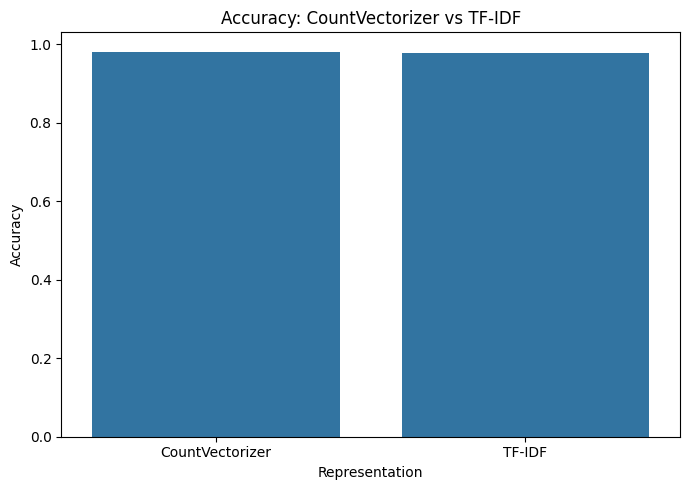

In [97]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=text_results_df,
    x="Representation",
    y="Accuracy"
)

plt.title("Accuracy: CountVectorizer vs TF-IDF")
plt.ylabel("Accuracy")
plt.xlabel("Representation")

plt.tight_layout()
plt.show()

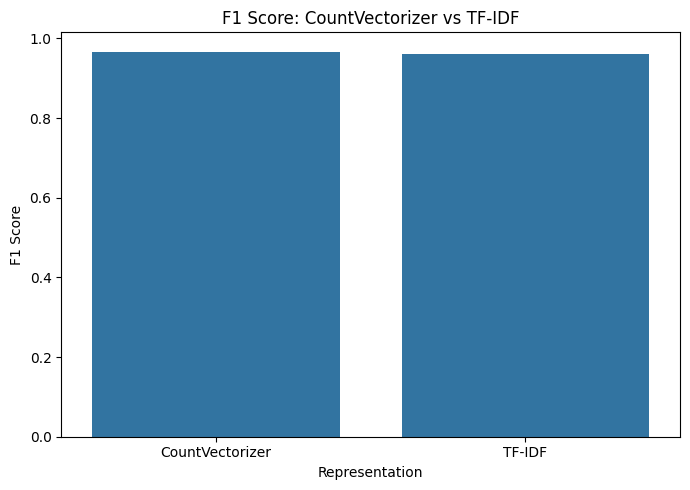

In [98]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=text_results_df,
    x="Representation",
    y="F1 Score"
)

plt.title("F1 Score: CountVectorizer vs TF-IDF")
plt.ylabel("F1 Score")
plt.xlabel("Representation")

plt.tight_layout()
plt.show()

In [99]:
improved_tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english"
)

X_train_improved_tfidf = improved_tfidf_vectorizer.fit_transform(
    X_train_text
)

X_test_improved_tfidf = improved_tfidf_vectorizer.transform(
    X_test_text
)

print(
    "Improved TF-IDF train shape:",
    X_train_improved_tfidf.shape
)

print(
    "Improved TF-IDF test shape:",
    X_test_improved_tfidf.shape
)

Improved TF-IDF train shape: (4137, 34475)
Improved TF-IDF test shape: (1035, 34475)


In [100]:
improved_tfidf_feature_count = (
    X_train_improved_tfidf.shape[1]
)

print(
    "Improved feature count:",
    improved_tfidf_feature_count
)

Improved feature count: 34475


In [101]:
improved_tfidf_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

start_train = time.perf_counter()

improved_tfidf_model.fit(
    X_train_improved_tfidf,
    y_train_text
)

improved_tfidf_train_time = (
    time.perf_counter() - start_train
)

start_pred = time.perf_counter()

improved_tfidf_pred = improved_tfidf_model.predict(
    X_test_improved_tfidf
)

improved_tfidf_prediction_time = (
    time.perf_counter() - start_pred
)

/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: invalid value encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)


In [102]:
improved_tfidf_accuracy = accuracy_score(
    y_test_text,
    improved_tfidf_pred
)

improved_tfidf_precision = precision_score(
    y_test_text,
    improved_tfidf_pred,
    zero_division=0
)

improved_tfidf_recall = recall_score(
    y_test_text,
    improved_tfidf_pred,
    zero_division=0
)

improved_tfidf_f1 = f1_score(
    y_test_text,
    improved_tfidf_pred,
    zero_division=0
)

print(f"Accuracy:  {improved_tfidf_accuracy:.4f}")
print(f"Precision: {improved_tfidf_precision:.4f}")
print(f"Recall:    {improved_tfidf_recall:.4f}")
print(f"F1 Score:  {improved_tfidf_f1:.4f}")
print(f"Training Time: {improved_tfidf_train_time:.6f} s")
print(f"Prediction Time: {improved_tfidf_prediction_time:.6f} s")

Accuracy:  0.9700
Precision: 0.9468
Recall:    0.9500
F1 Score:  0.9484
Training Time: 0.141002 s
Prediction Time: 0.000398 s


In [103]:
text_improvement_df = pd.DataFrame([
    {
        "Approach": "Original TF-IDF",
        "Features": tfidf_feature_count,
        "Accuracy": tfidf_accuracy,
        "Precision": tfidf_precision,
        "Recall": tfidf_recall,
        "F1 Score": tfidf_f1,
        "Training Time (s)": tfidf_train_time,
        "Prediction Time (s)": tfidf_prediction_time
    },
    {
        "Approach": "Improved TF-IDF",
        "Features": improved_tfidf_feature_count,
        "Accuracy": improved_tfidf_accuracy,
        "Precision": improved_tfidf_precision,
        "Recall": improved_tfidf_recall,
        "F1 Score": improved_tfidf_f1,
        "Training Time (s)": improved_tfidf_train_time,
        "Prediction Time (s)": improved_tfidf_prediction_time
    }
])

display(
    text_improvement_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Training Time (s)": "{:.6f}",
        "Prediction Time (s)": "{:.6f}"
    })
)

,Approach,Features,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Original TF-IDF,2974,0.9768,0.9510,0.9700,0.9604,0.022609,0.000408
1,Improved TF-IDF,34475,0.9700,0.9468,0.9500,0.9484,0.141002,0.000398


In [104]:
text_improvement_df.to_csv(
    RESULT_OUTPUT / "text_representation_improvement.csv",
    index=False
)

In [105]:
feature_change = (
    improved_tfidf_feature_count
    - tfidf_feature_count
)

accuracy_change = (
    improved_tfidf_accuracy
    - tfidf_accuracy
)

f1_change = (
    improved_tfidf_f1
    - tfidf_f1
)

training_time_change = (
    improved_tfidf_train_time
    - tfidf_train_time
)

print("Feature count change:", feature_change)
print("Accuracy change:", accuracy_change)
print("F1 change:", f1_change)
print("Training-time change:", training_time_change)

Feature count change: 31501
Accuracy change: -0.006763285024154575
F1 change: -0.011976738439234857
Training-time change: 0.11839300000019648


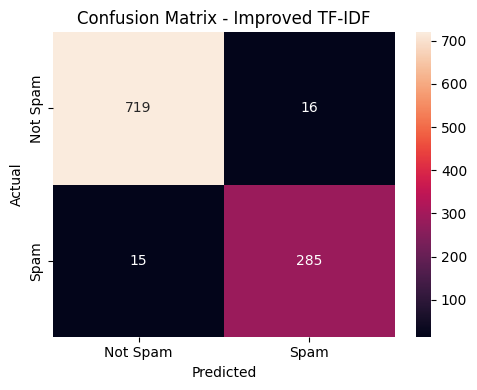

In [106]:
cm = confusion_matrix(
    y_test_text,
    improved_tfidf_pred
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Improved TF-IDF")

plt.tight_layout()

plt.savefig(
    RESULT_OUTPUT / "improved_tfidf_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Dataset Representation Note

The supplied email dataset contains 5,172 emails represented by a
3,000-word frequency matrix together with an email identifier and binary
prediction label.

Because the laboratory requires CountVectorizer and TF-IDF experiments,
text-like documents were reconstructed from the supplied word-frequency
representation before applying the required vectorization methods.

This reconstruction is documented explicitly so that the distinction
between the supplied representation and the experimentally generated
representations is clear.

In [107]:
print(text_results_df)
print("\n")
print(text_improvement_df)

    Representation  Features  Accuracy  Precision  Recall  F1 Score  \
0  CountVectorizer      2974  0.980676   0.954545    0.98  0.967105   
1           TF-IDF      2974  0.976812   0.950980    0.97  0.960396   

   Training Time (s)  Prediction Time (s)  
0           0.146906             0.000259  
1           0.022609             0.000408  


          Approach  Features  Accuracy  Precision  Recall  F1 Score  \
0  Original TF-IDF      2974  0.976812   0.950980    0.97  0.960396   
1  Improved TF-IDF     34475  0.970048   0.946844    0.95  0.948419   

   Training Time (s)  Prediction Time (s)  
0           0.022609             0.000408  
1           0.141002             0.000398  


In [108]:
print(image_results_df)
print("\n")
print(comparison_df)

                 Model  Accuracy  Precision  Recall  F1 Score  \
0  Logistic Regression    0.9375   0.948718   0.925  0.936709   
1        Random Forest    0.9625   0.951220   0.975  0.962963   
2                  SVM    0.9625   0.951220   0.975  0.962963   

   Training Time (s)  Prediction Time (s)  
0           0.013327             0.004093  
1           0.109012             0.015319  
2           0.001821             0.000635  


             Representation                Model  Accuracy  Precision  Recall  \
0  Original Canny (100,200)  Logistic Regression    0.9375   0.948718   0.925   
1  Original Canny (100,200)        Random Forest    0.9625   0.951220   0.975   
2  Original Canny (100,200)                  SVM    0.9625   0.951220   0.975   
3   Improved Canny (50,150)  Logistic Regression    0.9375   0.948718   0.925   
4   Improved Canny (50,150)        Random Forest    0.9375   0.926829   0.950   
5   Improved Canny (50,150)                  SVM    0.9625   0.951220   0.9

In [109]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Get project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Actual dataset paths
CRACK_DIR = PROJECT_ROOT / "data" / "asphalt" / "Cracks"

# Output directory
IMAGE_OUTPUT = PROJECT_ROOT / "outputs" / "images"
IMAGE_OUTPUT.mkdir(parents=True, exist_ok=True)

# Select first crack image
sample_path = crack_images[0]

print("Sample image:")
print(sample_path)

print("\nOutput directory:")
print(IMAGE_OUTPUT)

Sample image:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/data/asphalt/Cracks/IMG_8530 resized_448.jpg

Output directory:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs/images


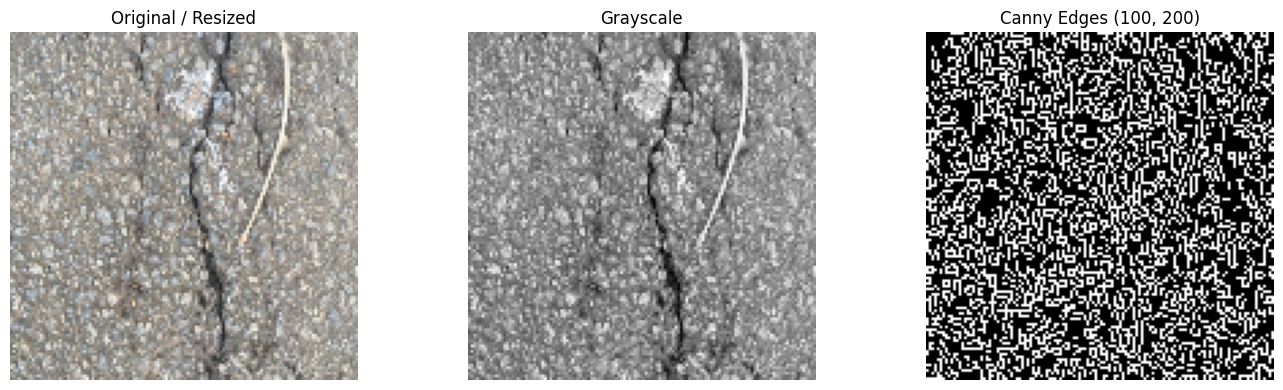

Saved successfully:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs/images/sample_canny.png
File exists: True


In [110]:
# Read image
image = cv2.imread(str(sample_path))

if image is None:
    raise ValueError(f"Could not read image: {sample_path}")

# Resize
resized = cv2.resize(image, (128, 128))

# Convert BGR -> RGB for matplotlib
rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

# Grayscale
gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

# Canny edges
edges = cv2.Canny(gray, 100, 200)

# Create visualization
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(rgb)
axes[0].set_title("Original / Resized")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")
axes[1].axis("off")

axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Canny Edges (100, 200)")
axes[2].axis("off")

plt.tight_layout()

# Save
output_path = IMAGE_OUTPUT / "sample_canny.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved successfully:")
print(output_path)
print("File exists:", output_path.exists())

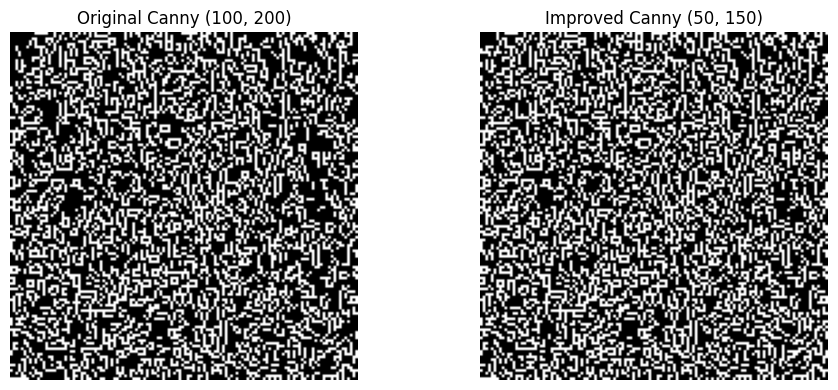

Saved:
/Users/divyshah/Desktop/DS605_Lab6_Image_Text_Feature_Extraction/outputs/images/original_vs_improved_canny.png


In [111]:
# Improved Canny
improved_edges = cv2.Canny(
    gray,
    50,
    150
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(edges, cmap="gray")
axes[0].set_title("Original Canny (100, 200)")
axes[0].axis("off")

axes[1].imshow(improved_edges, cmap="gray")
axes[1].set_title("Improved Canny (50, 150)")
axes[1].axis("off")

plt.tight_layout()

improved_output_path = (
    IMAGE_OUTPUT / "original_vs_improved_canny.png"
)

plt.savefig(
    improved_output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(improved_output_path)